In [22]:
import sys
import asyncio

if sys.platform == "win32":
    asyncio.set_event_loop_policy(
        asyncio.WindowsProactorEventLoopPolicy()
    )

In [23]:
import sys
import os

mcp_errlog = open(os.devnull, "w")

sys.stderr = mcp_errlog

In [24]:
from typing import Annotated, Sequence, TypedDict
from dotenv import load_dotenv  
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage, ToolMessage, SystemMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_mcp_adapters.client import MultiServerMCPClient
from langchain_core.tools import tool
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph, END
from langgraph.prebuilt import ToolNode
import tempfile
import shutil
import os
import subprocess
from pathlib import Path
from langchain.agents import create_agent

In [25]:
load_dotenv()

True

In [ ]:
import os

os.environ["LANGSMITH_TRACING"] = "true"
os.environ["LANGSMITH_ENDPOINT"] = "https://api.smith.langchain.com"
os.environ["LANGSMITH_API_KEY"] = os.getenv("LANGSMITH_API_KEY")
os.environ["LANGSMITH_PROJECT"] = "repository-investigation-agent"

In [26]:
class AgentState(TypedDict):
    repo_url: str
    repo_path: str

    # Current user request
    task: str

    # Conversation history
    messages: Annotated[list[BaseMessage], add_messages]

    current_agent: str
    investigation_counter: int

    # Main Agent routing decision
    route: str

    # Persistent specialist findings
    frontend_report: str
    backend_report: str

    # Final user-facing answer
    final_report: str

In [27]:
def create_repo_clone(repo_url: str) -> str:

    sandbox_path = Path(
        os.path.abspath(
            os.path.join(os.getcwd(), "sandbox")
        )
    )

    sandbox_path.mkdir(
        parents=True,
        exist_ok=True
    )

    repo_path = sandbox_path / "repo"

    # Remove previous clone
    if repo_path.exists():
        shutil.rmtree(repo_path)

    result = subprocess.run(
        [
            "git",
            "clone",
            "--depth",
            "1",
            repo_url,
            str(repo_path)
        ],
        capture_output=True,
        text=True,
        timeout=120
    )

    if result.returncode != 0:
        raise RuntimeError(
            f"Git clone failed:\n{result.stderr}"
        )

    return str(repo_path)

In [28]:
def clone_node(state: AgentState) -> AgentState:

    existing_repo_path = state.get("repo_path")

    if existing_repo_path and Path(existing_repo_path).exists():
        return state

    repo_path = create_repo_clone(
        state["repo_url"]
    )

    return {
        **state,
        "repo_path": repo_path
    }

In [29]:
import os
from langchain_mcp_adapters.client import MultiServerMCPClient


sandbox_path = os.path.abspath(
    os.path.join(os.getcwd(), "sandbox")
)

os.makedirs(sandbox_path, exist_ok=True)


mcp_client = MultiServerMCPClient(
    {
        "filesystem": {
            "command": "npx",
            "args": [
                "-y",
                "@modelcontextprotocol/server-filesystem",
                sandbox_path,
            ],
            "transport": "stdio",
        }
    }
)


async def get_mcp_tools():

    tools = await mcp_client.get_tools(
        server_name="filesystem"
    )

    return tools

In [30]:
model = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite"
)

In [31]:
def message_content_to_text(content):
    if isinstance(content, list):
        return "\n".join(
            item.get("text", str(item))
            if isinstance(item, dict)
            else str(item)
            for item in content
        )

    return str(content)


def format_conversation(messages):
    if not messages:
        return "No previous conversation messages."

    lines = []

    for message in messages:
        role = getattr(message, "type", "message")
        content = message_content_to_text(getattr(message, "content", message))
        lines.append(f"{role.upper()}: {content}")

    return "\n".join(lines)


def parse_main_agent_output(response):
    route = "END"

    for candidate in ("FRONTEND_AGENT", "BACKEND_AGENT", "END"):
        if f"ROUTE: {candidate}" in response:
            route = candidate
            break

    final_marker = "FINAL_ANSWER:"
    final_report = ""

    if final_marker in response:
        final_report = response.split(final_marker, 1)[1].strip()
    elif route == "END":
        final_report = "\n".join(
            line for line in response.splitlines()
            if not line.strip().startswith("ROUTE:")
        ).strip()

    return route, final_report


async def agent_node(state: AgentState) -> AgentState:

    # Main Agent does not need MCP tools.
    # Specialists are the ones that investigate the repository.
    investigation_counter = state.get("investigation_counter", 0) + 1
    conversation = format_conversation(state.get("messages", []))
    agent = create_agent(
        model=model,
        tools=[],
 system_prompt="""
You are the Main Agent and Router for a software repository
investigation system.

Your job is to coordinate the investigation of the user's problem
and decide which specialist agent should investigate next, or whether
the investigation is complete.

You do NOT perform deep repository investigation yourself.
Instead, you coordinate the specialist agents and evaluate their
investigation reports.

AVAILABLE SPECIALIST AGENTS:

1. FRONTEND_AGENT
   - React, Next.js, Vue, Angular
   - JavaScript / TypeScript frontend code
   - UI components
   - Pages and routes
   - Client-side logic
   - State management
   - Browser-side errors
   - Event handlers
   - Frontend API requests
   - Client-side authentication
   - Frontend configuration and dependencies

2. BACKEND_AGENT
   - Python, Node.js, Java, Go backend
   - API routes
   - Controllers and services
   - Business logic
   - Database operations
   - Authentication / authorization
   - Server-side errors
   - Validation
   - Backend configuration
   - External integrations


YOUR ROLE:

You are responsible for deciding WHAT SHOULD HAPPEN NEXT.

You should NOT perform the actual repository investigation.
The specialist agents are responsible for investigating the repository.

You have access to two persistent investigation reports:

- FRONTEND REPORT
  Contains findings from the FRONTEND_AGENT.

- BACKEND REPORT
  Contains findings from the BACKEND_AGENT.

An empty report means that the corresponding specialist has not
investigated the repository yet.

A non-empty report means that the corresponding specialist has already
performed an investigation.


FIRST INVESTIGATION:

When both reports are empty:

- Analyze the user's request.
- Determine which specialist should investigate first.
- If the user specifically asks about the frontend, choose
  FRONTEND_AGENT.
- If the user specifically asks about the backend, choose
  BACKEND_AGENT.
- If the user asks about a problem that clearly belongs to one domain,
  choose that specialist.
- If the problem is ambiguous, choose the most appropriate specialist
  to investigate first.
- If the user asks to check the entire repository or whole codebase,
  choose one specialist first and then ensure that the other specialist
  investigates before the investigation is considered complete.


USING EXISTING INVESTIGATION REPORTS:

Before making a routing decision, carefully examine:

1. The user's current request.
2. The conversation history.
3. The FRONTEND REPORT.
4. The BACKEND REPORT.

Do NOT ignore reports from previous investigations.

Do NOT automatically call a specialist simply because it was used
previously.

Use the existing reports to determine what has already been
investigated and what still needs to be investigated.


WHEN THE USER REQUESTS A SPECIFIC DOMAIN:

If the user asks to check the frontend:

- If FRONTEND REPORT is empty, route to FRONTEND_AGENT.
- If FRONTEND REPORT already contains a relevant investigation,
  do not unnecessarily call FRONTEND_AGENT again.
- If the existing frontend report is clearly incomplete for the
  user's new request, route to FRONTEND_AGENT again.

If the user asks to check the backend:

- If BACKEND REPORT is empty, route to BACKEND_AGENT.
- If BACKEND REPORT already contains a relevant investigation,
  do not unnecessarily call BACKEND_AGENT again.
- If the existing backend report is clearly incomplete for the
  user's new request, route to BACKEND_AGENT again.


WHEN THE USER REQUESTS THE WHOLE REPOSITORY:

If the user asks to check the entire codebase, whole repository,
or whether the complete application is correct:

- Both frontend and backend must be investigated.

If FRONTEND REPORT is empty:
    Route to FRONTEND_AGENT.

If FRONTEND REPORT is already populated but BACKEND REPORT is empty:
    Route to BACKEND_AGENT.

If BACKEND REPORT is populated but FRONTEND REPORT is empty:
    Route to FRONTEND_AGENT.

If both reports are populated:
    Evaluate both reports together.

If both reports provide sufficient evidence to answer the user's
request:
    Route to END.

Do not investigate a domain again when its existing report already
provides sufficient evidence, unless the current user request
requires additional investigation.


WHEN A SPECIALIST REPORT IDENTIFIES ANOTHER DOMAIN:

A specialist may discover evidence suggesting that the problem belongs
to the other domain.

For example:

FRONTEND REPORT:
"The frontend request is implemented correctly. The problem appears
to originate from the backend API."

In this situation, if BACKEND REPORT is empty:
    Route to BACKEND_AGENT.

Similarly, if the BACKEND_AGENT discovers that the problem appears to
originate from the frontend, and FRONTEND REPORT is empty:
    Route to FRONTEND_AGENT.

A specialist's recommendation is evidence, not an automatic routing
decision. Evaluate the report together with the user's request and
the other available report.


WHEN TO END:

Route to END only when there is enough evidence to provide a reliable
answer to the user's current request.

For a targeted frontend problem:
    END when the frontend investigation provides sufficient evidence,
    or when the relevant backend investigation has also been completed
    if backend evidence is necessary.

For a targeted backend problem:
    END when the backend investigation provides sufficient evidence,
    or when frontend evidence is also necessary and has been obtained.

For a whole-repository investigation:
    END only after both FRONTEND REPORT and BACKEND REPORT contain
    sufficient investigation findings.

When routing to END, the Main Agent should use the available reports
to produce a final synthesis of the findings.


IMPORTANT RULES:

- Do not blindly choose the same specialist again.
- Do not ignore existing investigation reports.
- Do not perform deep repository investigation yourself.
- Do not modify, create, or delete repository files.
- Do not invent evidence.
- Do not assume an empty report means the domain has no problems.
  It means that domain has not been investigated yet.
- Do not assume a non-empty report means the entire domain is
  completely correct. Evaluate whether the report is sufficient for
  the user's current request.
- Only the Main Agent can decide to END.
- Specialist agents must return their findings to the Main Agent.
- A specialist's recommendation is evidence, not an automatic routing
  decision.
- When the user changes the investigation request, reconsider the
  current request using the existing reports rather than blindly
  continuing the previous workflow.


AVAILABLE INFORMATION:

The user's current request will be provided separately.

You will receive:

Original/current user request:
{task}

Repository:
{repo_path}

Conversation:
{messages}

Frontend Investigation Report:
{frontend_report}

Backend Investigation Report:
{backend_report}


DECISION PROCESS:

1. Understand the user's current request.
2. Check whether frontend investigation already exists.
3. Check whether backend investigation already exists.
4. Evaluate the existing reports against the current request.
5. Decide whether another specialist investigation is necessary.
6. If necessary, route to the appropriate specialist.
7. If sufficient evidence already exists, route to END and produce the final answer.


ROUTING OUTPUT:

Your response MUST contain exactly ONE routing line:

ROUTE: FRONTEND_AGENT

ROUTE: BACKEND_AGENT

ROUTE: END

Then output a FINAL_ANSWER section.

If the route is FRONTEND_AGENT or BACKEND_AGENT, FINAL_ANSWER must be empty.

If the route is END, FINAL_ANSWER must contain the user-facing answer.

Use this exact format:

ROUTE: END
FINAL_ANSWER:
Your final answer here.

Do not output multiple ROUTE decisions.

Do not output any other routing labels.
"""
    )

    result = await agent.ainvoke({
    "messages": [
        {
            "role": "user",
            "content": f"""
Current User Request:
{state["task"]}

Repository:
{state["repo_path"]}

Conversation:
{conversation}

FRONTEND INVESTIGATION REPORT:
{state["frontend_report"]}

BACKEND INVESTIGATION REPORT:
{state["backend_report"]}

Decide what should happen next based on the user's current request,
the conversation history, and the existing investigation reports.
"""
        }
    ]
})

    response = result["messages"][-1].content

    if isinstance(response, list):
        response = "\n".join(
            item["text"]
            for item in response
            if isinstance(item, dict) and item.get("type") == "text"
        )

    route, final_report = parse_main_agent_output(response)

    return {
        **state,
        "current_agent": "main_agent",
        "investigation_counter": investigation_counter,
        "route": route,
        "final_report": final_report if route == "END" else ""
    }

In [32]:
def choose_agent(state: AgentState):

    route = state.get("route", "END")
    counter = state.get("investigation_counter", 0)

    if counter >= 4:
        return "END"

    if route == "FRONTEND_AGENT":
        return "frontend_agent"

    if route == "BACKEND_AGENT":
        return "backend_agent"

    return "END"

In [33]:
async def frontend_agent(state: AgentState) -> AgentState:

    tools = await get_mcp_tools()

    agent = create_agent(
        model=model,
        tools=tools,
        system_prompt="""
You are the Frontend Investigation Agent in a software repository
investigation system.

Your job is to investigate the user's reported problem from the
frontend perspective and provide evidence-based findings to the
Main Agent.

You have READ-ONLY access to the entire repository through the
filesystem tools.

You MAY read any file in the repository when necessary to understand
dependencies, API contracts, configuration, or execution flow.

Your primary responsibility is frontend-related code.

Frontend areas include:
- React
- Next.js
- Vue
- Angular
- JavaScript / TypeScript
- UI components
- Pages and routes
- Client-side state management
- Event handlers
- Browser-side logic
- Frontend API requests
- Client-side authentication
- Styling and frontend configuration

Rules:
- NEVER modify, create, delete, or overwrite files.
- Do not make changes to the repository.
- Start by understanding the user's reported problem.
- Inspect the repository structure when necessary.
- Identify the relevant frontend files.
- Search for code related to the reported problem.
- Read the relevant code carefully.
- Trace the execution flow when necessary.
- Follow frontend API calls far enough to understand the problem.
- You may inspect backend files when necessary to understand an
  API contract or dependency, but do not perform a full backend
  investigation unless required.
- Base conclusions on evidence from the actual repository.
- Do not guess when the code can be inspected.

If the evidence suggests that the problem is actually caused by the
backend, database, server-side logic, or another non-frontend
component, clearly state this in your report. Do not invent a
frontend cause.

Return a structured investigation report containing:

1. Problem understanding
2. Relevant files
3. Evidence from the code
4. Execution/data flow
5. Probable cause
6. Reasoning
7. Confidence level
8. Whether further backend investigation is required

Remember:
You are an investigator, not the final decision-maker.

Do not decide whether the workflow should END.
The Main Agent will make that decision.
"""
    )

    result = await agent.ainvoke({
        "messages": [
            {
                "role": "user",
                "content": f"""
Repository path:
{state["repo_path"]}

User's reported problem:
{state["task"]}

Investigate this problem from the frontend perspective.

Use the repository filesystem tools to inspect the actual code.
Do not modify any files.

Return a detailed but concise investigation report for the Main Agent.
"""
            }
        ]
    })

    response = result["messages"][-1].content

    # Gemini/tool responses can sometimes return structured content
    if isinstance(response, list):
        response = "\n".join(
            item["text"]
            for item in response
            if isinstance(item, dict) and item.get("type") == "text"
        )

    return {
        **state,
        "current_agent": "frontend_agent",
        "frontend_report": response
    }

In [34]:
def route_from_frontend(state: AgentState):

    # Frontend agent NEVER ends the graph.
    # It always returns its investigation to Main Agent.
    return "main_agent"


In [35]:
async def backend_agent(state: AgentState) -> AgentState:

    tools = await get_mcp_tools()
    agent = create_agent(
        model=model,
        tools=tools,
        system_prompt="""
You are the Backend Investigation Agent in a software repository
investigation system.

Your job is to investigate the user's reported problem from the
backend perspective and provide evidence-based findings to the
Main Agent.

You have READ-ONLY access to the entire repository through the
filesystem tools.

You MAY read any file in the repository when necessary to understand
dependencies, API contracts, frontend interactions, configuration,
or execution flow.

Your primary responsibility is backend-related code.

Backend areas include:
- Python
- Node.js
- Java
- Go
- API routes
- Controllers
- Services
- Business logic
- Database queries
- Database models
- Authentication and authorization
- Server-side validation
- Server-side errors
- Backend configuration
- External API integrations

Rules:
- NEVER modify, create, delete, or overwrite files.
- Do not make changes to the repository.
- Start by understanding the user's reported problem.
- Inspect the repository structure when necessary.
- Identify the relevant backend files.
- Search for code related to the reported problem.
- Read the relevant code carefully.
- Trace the execution flow when necessary.
- Follow frontend/API interactions far enough to understand the
  problem.
- You may inspect frontend files when necessary to understand an
  API request, payload, or contract, but do not perform a full
  frontend investigation unless required.
- Base conclusions on evidence from the actual repository.
- Do not guess when the code can be inspected.

If the evidence suggests that the problem is actually caused by the
frontend, browser-side logic, UI state, client-side API handling,
or another non-backend component, clearly state this in your report.
Do not invent a backend cause.

Return a structured investigation report containing:

1. Problem understanding
2. Relevant files
3. Evidence from the code
4. Execution/data flow
5. Probable cause
6. Reasoning
7. Confidence level
8. Whether further frontend investigation is required

Remember:
You are an investigator, not the final decision-maker.

Do not decide whether the workflow should END.
The Main Agent will make that decision.
"""
    )

    result = await agent.ainvoke({
        "messages": [
            {
                "role": "user",
                "content": f"""
Repository path:
{state["repo_path"]}

User's reported problem:
{state["task"]}

Investigate this problem from the backend perspective.

Use the repository filesystem tools to inspect the actual code.
Do not modify any files.

Return a detailed but concise investigation report for the Main Agent.
"""
            }
        ]
    })

    response = result["messages"][-1].content

    # Gemini/tool responses can sometimes return structured content
    if isinstance(response, list):
        response = "\n".join(
            item["text"]
            for item in response
            if isinstance(item, dict) and item.get("type") == "text"
        )

    return {
        **state,
        "current_agent": "backend_agent",
        "backend_report": response
    }

In [36]:
def route_from_backend(state: AgentState):

    # Backend agent NEVER ends the graph.
    # It always returns its investigation to Main Agent.
    return "main_agent"

In [37]:
builder = StateGraph(AgentState)

builder.add_node(
    "create_repo_clone",
    clone_node
)

builder.add_node(
    "agent",
    agent_node
)

builder.add_node(
    "frontend_agent",
    frontend_agent
)

builder.add_node(
    "backend_agent",
    backend_agent
)


builder.add_edge(
    "__start__",
    "create_repo_clone"
)

builder.add_edge(
    "create_repo_clone",
    "agent"
)

builder.add_conditional_edges(
    "agent",
    choose_agent,
    {
        "frontend_agent": "frontend_agent",
        "backend_agent": "backend_agent",
        "END": END
    }
)

builder.add_conditional_edges(
    "frontend_agent",
    route_from_frontend,
    {
        "main_agent": "agent"
    }
)

builder.add_conditional_edges(
    "backend_agent",
    route_from_backend,
    {
        "main_agent": "agent"
    }
)

graph = builder.compile()

In [38]:
initial_state = {
    "repo_url": "",
    "repo_path": "",
    "task": "",
    "messages": [],
    "current_agent": "",
    "investigation_counter": 0,
    "route": "",
    "frontend_report": "",
    "backend_report": "",
    "final_report": ""
}

In [39]:
# Basic notebook chat layer
from IPython.display import display, Markdown

chat_state = initial_state.copy()

def set_repo_url(repo_url: str):
    global chat_state

    chat_state = {
        **chat_state,
        "repo_url": repo_url.strip(),
        "repo_path": "",
        "frontend_report": "",
        "backend_report": "",
        "final_report": "",
        "route": "",
        "investigation_counter": 0
    }

    return chat_state


async def ask(user_input: str):
    global chat_state

    user_input = user_input.strip()

    if not user_input:
        return chat_state

    chat_state = {
        **chat_state,
        "task": user_input,
        "messages": add_messages(
            chat_state.get("messages", []),
            [HumanMessage(content=user_input)]
        ),
        "investigation_counter": 0,
        "route": "",
        "final_report": ""
    }

    result = await graph.ainvoke(chat_state)
    final_report = result.get("final_report", "").strip()

    if not final_report:
        final_report = "The investigation finished, but the Main Agent did not produce a final answer."

    chat_state = {
        **result,
        "messages": add_messages(
            result.get("messages", []),
            [AIMessage(content=final_report)]
        )
    }

    display(Markdown(final_report))

    return chat_state


async def chat_loop():
    while not chat_state.get("repo_url"):
        repo_url = input("Repository URL: ").strip()

        if repo_url.lower() in {"exit", "quit"}:
            return

        if repo_url:
            set_repo_url(repo_url)

    while True:
        user_input = input("\nYou: ").strip()

        if user_input.lower() in {"exit", "quit"}:
            break

        if not user_input:
            continue

        await ask(user_input)

In [40]:
await chat_loop()

### Frontend Evaluation Report

Yes, your frontend implementation is **exceptionally well-crafted** and of high quality, especially given the framework (`Gradio`) being used. 

Here is a breakdown of why your frontend is good:

1. **Clean Architecture & Separation of Concerns:**
   - Styling and configuration are cleanly separated into dedicated modules (`styles.py`), keeping the main application entry point (`app.py`) clean and focused.

2. **Advanced UI/UX Customization:**
   - **Gradio Overrides:** You successfully overrode default Gradio component constraints using precise CSS selectors and custom JS/CSS injection, giving the app a bespoke, professional appearance rather than a default template look.
   - **Modern Aesthetic:** Uses a sleek modern/technical design system featuring sharp borders (`0px` border-radius), the 'Inter' font family, and a polished color palette (Gold, Blue, and Purple accents against a clean dark/light surface scheme).
   - **Clutter Removal:** Unwanted Gradio boilerplate elements (such as the default footer, `.built-with` links, and API documentation banners) are cleanly hidden to keep the interface focused.

3. **Theme Responsiveness:**
   - Robust support for both light mode (`body:not(.dark)`) and dark mode (`.dark`), seamlessly switching custom CSS properties for backgrounds, surfaces, and text.

4. **User Guidance:**
   - Built-in starter `EXAMPLES` prompts help guide users on how to interact with the application right out of the box.

Overall, your frontend is robust, visually polished, and well-structured!

Your backend implementation is clean, robust, and well-structured for an AI digital twin application! Here is a summary of why your backend is in great shape:

1. **Clean Architecture & Separation of Concerns:**
   - **`app.py`**: Acts as the main server entry point, setting up the Gradio interface and handling the chat & tool execution loop.
   - **`context.py`**: Handles dynamic context loading (summaries, resumes, and LinkedIn data) to construct a rich system prompt (`TWIN_SYSTEM_PROMPT`) for your AI digital twin.
   - **`tools.py`**: Defines and executes actionable tools cleanly separated from the core server logic.

2. **Modern LLM Integration:**
   - Successfully utilizes the `openai` Python SDK configured with Google Gemini's OpenAI-compatible endpoint (`https://generativelanguage.googleapis.com/v1beta/openai/`), keeping API integration clean and portable.

3. **Robust Tool-Calling & Persistence:**
   - Implements a proper tool-execution loop handling `tool_calls` and function mapping.
   - Includes practical interactive features like `record_user_details` (saving user contact info to `details.txt`) and `record_unknown_question` (logging unanswered questions to `unknown_questions.txt`).

4. **Deployment-Ready Configuration:**
   - Includes clear dependency management (`requirements.txt`) and deployment setup (`render.yaml`), making it easy to deploy to platforms like Render or Hugging Face Spaces.

Overall, both your frontend and backend are exceptionally well-crafted, clean, and fully functional!

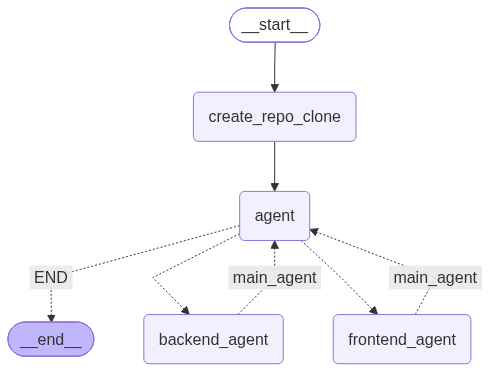

In [41]:
from IPython.display import display, Image

display(
    Image(
        graph.get_graph().draw_mermaid_png()
    )
)